# Token embedding

In the previous part, we used a recurrent neural network (RNN) to let a model read Shakespeare for the first time. But an RNN has two inherent flaws:

* **Limited memory**: all the history has to be compressed into a hidden state of fixed length. The more information is stuffed in, the sooner the early content is squeezed out;
* **No parallelism**: tokens must be processed one by one in order, and the next cannot start before the previous one has finished. With massive amounts of text, training speed becomes an insurmountable bottleneck.

In 2017, a research team at Google published the famous paper *Attention Is All You Need*, which proposed the brand-new Transformer architecture: it abandons recurrence entirely and relies completely on the **attention mechanism** to process token sequences. The **Generative Pre-trained Transformer** (GPT), born from this architecture, opened the era of large language models.

---

From this part on, we will build a real GPT model step by step:

* **Input representation**: token embedding and position embedding, which turn text into vectors that carry information;
* **Self-attention**: causal, weighted, and multi-head, which let tokens attend to each other and understand context;
* **Pre-training**: residual connections, normalization, and dropout, which make the model deeper, bigger, and well trained;
* **Inference**: sampling strategies, stopping criteria, the KV cache, and batch inference, which control generation and make it more efficient;
* **Fine-tuning**: supervised fine-tuning and preference optimization, which teach the model to move from the pre-trained "continue the text" mode to a "conversation" mode.

In this chapter, we take the first step: building the most basic framework and connecting the dataset through **token embedding**.

In [1]:
import numpy as np

from src.core import *

> 💡 **Tip**: By importing `src.core`, we can directly use the model training framework built in the previous chapters.

In [2]:
np.random.seed(42)

## Dataset

### Character-encoding dataset

The GPT dataset is exactly the same as the RNN dataset, and needs no modification:

* `vocab` (vocabulary): tokenized by character;
* `tokens` (token table): the whole text converted into a sequence of index encodings;
* $x$ (feature): a token sequence cut from the text, `tokens[i: i + context_size]`;
* $y$ (label): the feature token sequence shifted as a whole by one position, `tokens[i + 1: i + context_size + 1]`.

That is, each sample contains `context_size` prediction tasks: predict the 2nd token from the 1st, the 3rd token from the first 2, and so on, up to predicting token `context_size + 1` from the first `context_size` tokens.

This way of training, predicting the next token from what is already there, is called **autoregressive** training, and it is the core training paradigm of GPT. Unlike an RNN, which must compute token by token in order, GPT can process all the tokens of a sample in parallel in one go.

In [3]:
class CharDataset(Dataset):

    def __init__(self, filename, batch_size=1, context_size=64, stride=None, split=0.9):
        self.filename = filename
        self.context_size = context_size
        self.stride = stride if stride is not None else context_size // 2
        self.split = split
        super().__init__(batch_size)

    def load(self):
        with open(self.filename, encoding="utf-8") as f:
            text = f.read()

        self.vocab = sorted(set(text))
        self.vocab_size = len(self.vocab)
        self.stoi = {ch: i for i, ch in enumerate(self.vocab)}
        self.itos = {i: ch for i, ch in enumerate(self.vocab)}
        self.tokens = self.encode(text)

        split = int(len(self.tokens) * self.split)
        self.train_data = self._pack(self.tokens[:split])
        self.test_data = self._pack(self.tokens[split:])

    def _pack(self, tokens):
        x, y = [], []
        for i in range(0, len(tokens) - self.context_size - 1, self.stride):
            x.append(tokens[i: i + self.context_size])
            y.append(tokens[i + 1: i + self.context_size + 1])
        return x, y

    def encode(self, symbols):
        return [self.stoi[s] for s in symbols]

    def decode(self, tokens):
        return "".join(self.itos[t] for t in tokens)

## Activation functions

### Gaussian error linear unit (GELU)

So far, we have used ReLU as the hidden layer activation function. GPT uses an upgraded version: the **Gaussian error linear unit** (GELU).

The curve of GELU is very similar to that of ReLU: negative numbers are mostly filtered to 0, and positive numbers are kept as they are. The difference is that GELU bends smoothly around the origin, without the sharp kink of ReLU. The smooth curve makes the gradient change more steadily, which helps the training of deep models such as GPT.

---

**Forward propagation**: the exact definition of GELU needs the cumulative distribution function of the Gaussian distribution, which is expensive to compute. In practice, an approximation is usually used:

$$
\text{GELU}(x) \approx 0.5 \, x \left( 1 + \tanh\left( \sqrt{\frac{2}{\pi}} \left( x + 0.044715 \, x^3 \right) \right) \right)
$$

**Gradient computation**: the gradient function `gradient_fn` of backpropagation is also the derivative of this approximation.

In [4]:
class GELU(Layer):

    def __init__(self):
        super().__init__()
        self.c = np.sqrt(2.0 / np.pi)

    def forward(self, x: Tensor):
        # Create the activation tensor
        tanh = np.tanh(self.c * (x.data + 0.044715 * x.data ** 3))
        a = Tensor(0.5 * x.data * (1.0 + tanh))

        # Gradient (closure) function of the activation tensor
        def gradient_fn():
            grad = 0.5 * (1.0 + tanh) + 0.5 * x.data * (1.0 - tanh ** 2) * self.c * (1.0 + 3.0 * 0.044715 * x.data ** 2)
            x.grad += a.grad * grad

        # Set the gradient (closure) function and parent list of the activation tensor
        return a.attach(gradient_fn, parents=[x])

Let us look at the effect of the GELU activation function:

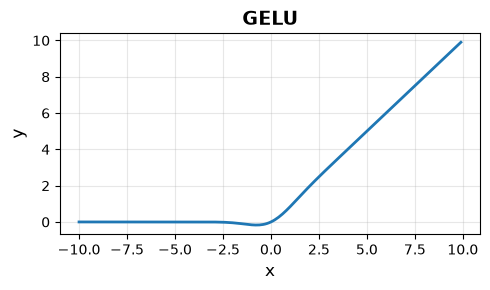

In [5]:
import matplotlib.pyplot as plt

gelu = GELU()

plt.figure(figsize=(5, 3))
x_range = np.arange(-10, 10, 0.1)
plt.plot(x_range, [gelu(Tensor(x)).data for x in x_range], linewidth=2)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('GELU', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Loss function

### GPT cross-entropy loss function

An RNN model computes token by token, so we also computed the cross-entropy loss token by token and then added the losses up.

A GPT model can compute all the tokens of a sample at once and outputs many predictions, with the shape `(batch size, context size, vocabulary size)`. In practice, we can flatten both the predictions and the labels into one big 2-dimensional array with the shape `(batch size * context size, vocabulary size)`, and use the vectorized operations of NumPy to compute the whole cross-entropy loss at once.

`GPTLoss` is the upgraded version of the cross-entropy loss function, computing all the positions of a batch of samples at once.

In [6]:
class GPTLoss(Loss):

    def loss(self, p: Tensor, y: Tensor):
        # Built-in Softmax
        exp = np.exp(p.data - np.max(p.data, axis=-1, keepdims=True))
        softmax = exp / np.sum(exp, axis=-1, keepdims=True)

        # Flatten
        flat_softmax = softmax.reshape(-1, softmax.shape[-1])
        flat_y = y.data.reshape(-1).astype(np.int64)
        n = len(flat_y)
        rows = np.arange(n)

        # Create the loss tensor
        log = np.log(np.clip(flat_softmax[rows, flat_y], 1e-10, 1))
        ce = Tensor(0 - np.sum(log) / n)

        # Gradient (closure) function of the loss tensor
        def gradient_fn():
            flat_grad = flat_softmax.copy()
            flat_grad[rows, flat_y] -= 1
            p.grad += ce.grad * flat_grad.reshape(softmax.shape) / n

        # Set the gradient (closure) function and parent list of the loss tensor
        return ce.attach(gradient_fn, parents=[p])

## Model

A complete GPT model consists of three modules:

* `Embedding` (embedding layer): converts the index encodings of the input text into word vectors;
* `Transformer` (Transformer block): called many times in a loop, refining features from the word vectors layer by layer;
* `Output` (output layer): maps the word vectors to probabilities over the vocabulary.

<div style="text-align: center;">
  <img src="images/token-embedding.png" alt="Basic modules of GPT: the embedding layer, the Transformer block, and the output layer">
  <div>Figure: Basic modules of GPT</div>
</div>

### GPT embedding layer

The **GPT embedding layer** is the first layer of the GPT model. It converts the index encodings of the whole text into dense word vectors.

Unlike the RNN model, it no longer uses a mean pooling layer to merge all the word vectors of the text into one bag-of-words vector, which would lose the word order. The GPT model keeps the word vector of every token, so the word order information runs through the whole model.

In [7]:
class GPTEmbedding(Composite):

    def __init__(self, vocab_size, embedding_size):
        # Token embedding layer
        self.embedding = Embedding(vocab_size, embedding_size)

        super().__init__([self.embedding])

    def forward(self, x: Tensor):
        return self.embedding(x)

### GPT feed-forward network layer

The **GPT feed-forward network layer** (FFN) is a standard two-layer fully connected network: a linear hidden layer + a GELU activation function + a linear output layer. It digs out the inner logic of the data.

> 💡 **Tip**: The hidden layer of the feed-forward network layer expands the data size by a factor of 4, and the output layer then compresses it back to the original size, so that the data can connect smoothly from layer to layer. This is also the standard configuration of GPT models.

In [8]:
class GPTFeedForward(Composite):

    def __init__(self, embedding_size):
        # Hidden layer
        self.input = Linear(embedding_size, embedding_size * 4)
        # Hidden layer activation function
        self.gelu = GELU()
        # Output layer
        self.output = Linear(embedding_size * 4, embedding_size)

        super().__init__([self.input,
                          self.gelu,
                          self.output])

    def forward(self, x: Tensor):
        h = self.gelu(self.input(x))
        return self.output(h)

### GPT Transformer block

The **GPT Transformer block** is the core component of the GPT model. For now it contains only a feed-forward network layer, and we will extend it with the attention mechanism later.

Although a GPT model can process all the tokens of a sample in parallel in one go, a single pass obviously cannot train it fully. So the Transformer block is called many times in a loop, gradually refining the inner logic of the data.

In [9]:
class GPTTransformer(Composite):

    def __init__(self, embedding_size):
        # Feed-forward network layer
        self.feed_forward = GPTFeedForward(embedding_size)

        super().__init__([self.feed_forward])

    def forward(self, x: Tensor):
        return self.feed_forward(x)

### GPT output layer

The main body of the **GPT output layer** is a linear layer. It maps the word vector at each position to a vector of the vocabulary size, matching the label. The output values are **logits**. After conversion by the Softmax activation function included in the cross-entropy loss function, each value finally represents the probability of the corresponding token.

In [10]:
class GPTOutput(Composite):

    def __init__(self, embedding_size, vocab_size):
        # Output layer
        self.output = Linear(embedding_size, vocab_size)

        super().__init__([self.output])

    def forward(self, x: Tensor):
        return self.output(x)

### GPT model

Finally, we assemble the three parts into the complete GPT model, which includes several Transformer blocks to refine the features of the data many times.

As data moves through the parts of the model, its shape changes too:

$$
(\text{batch}, \text{context}) \xrightarrow{\text{embedding}} (\text{batch}, \text{context}, \text{embedding}) \xrightarrow{\text{Transformer block} \times n} (\text{batch}, \text{context}, \text{embedding}) \xrightarrow{\text{output}} (\text{batch}, \text{context}, \text{vocabulary})
$$

We can see that the sequence dimensions `(batch size, context size)` stay unchanged from beginning to end. Every position completes its own prediction independently, which is exactly the key to why GPT can be trained in parallel.

In [11]:
class GPT(Composite):

    def __init__(self, vocab_size, embedding_size, blocks):
        # Embedding layer
        self.embedding = GPTEmbedding(vocab_size, embedding_size)
        # Multiple Transformer blocks
        self.transformers = [GPTTransformer(embedding_size) for _ in range(blocks)]
        # Output layer
        self.output = GPTOutput(embedding_size, vocab_size)

        super().__init__([self.embedding] + self.transformers + [self.output])

    def forward(self, x: Tensor):
        x = self.embedding(x)
        for layer in self.transformers:
            x = layer(x)
        return self.output(x)

## GPT trainer

The GPT trainer is much the same as the RNN trainer, with three notable differences:

* **Loss computation**: there is no more looping over time steps; a single call to the loss function computes all the positions;
* **Disabling gradients**: during evaluation and text generation, there is no need to build the computational graph or backpropagate. We use the function `Tensor.no_grad` provided by the framework to switch off gradient computation temporarily, saving memory and compute;
* **Text generation**: the generation method `generate` implements the **autoregressive generation** of GPT:
    * encode the prompt `prompt` into a token sequence;
    * each time, take the last `context_size` tokens as the input and run the model;
    * take only the logits of the last position of the prediction, convert them into a probability distribution, and sample the next token at random;
    * append the new token to the end of the token sequence, and repeat the process.

> 💡 **Tip**: Generating text by random sampling instead of always taking the most probable token lets each generation be worded differently and keeps the model from falling into repetition.

In [12]:
class GPTTrainer(Trainer):

    def train(self, dataset, epochs, scheduler=None):
        # Training set
        dataset.train()
        # Training mode
        self.model.train()

        steps = 0
        for epoch in range(epochs):
            for i in range(len(dataset)):
                if scheduler is not None:
                    self.optimizer.lr = scheduler.step(steps)

                feature, label = dataset[i]

                self.optimizer.zero_grad()
                prediction = self.model(feature)
                loss = self.loss_fn(prediction, label)
                loss.backward()
                self.optimizer.clip_grad_norm()
                self.optimizer.step()
                steps += 1

    def test(self, dataset):
        # Test set
        dataset.eval()
        # Inference mode
        self.model.eval()

        predictions = []
        total_loss = 0.0
        # Disable gradients
        with Tensor.no_grad():
            for i in range(len(dataset)):
                feature, label = dataset[i]
                prediction = self.model(feature)
                loss = self.loss_fn(prediction, label)
                predictions.append(prediction)
                total_loss += float(loss.data)

        loss = total_loss / len(dataset)
        dataset.train()
        self.model.train()
        return predictions, loss

    def generate(self, dataset, prompt, steps=256):
        # Inference mode
        self.model.eval()
        tokens = dataset.encode(prompt)

        # Disable gradients
        with Tensor.no_grad():
            for _ in range(steps):
                feature = Tensor([tokens[-dataset.context_size:]])
                logits = self.model(feature)

                last_logits = logits.data[0, -1]
                exp = np.exp(last_logits - np.max(last_logits))
                probs = exp / np.sum(exp)
                token = np.random.choice(len(probs), p=probs)
                tokens.append(token)

        return dataset.decode(tokens)

## Hyperparameters

### Learning rate

In [13]:
LEARNING_RATE = 0.001

### Batch size

In [14]:
BATCH_SIZE = 4

### Number of epochs

In [15]:
EPOCHS = 2

### Context size

In [16]:
CONTEXT_SIZE = 32

### Embedding size

In [17]:
EMBEDDING_SIZE = 64

### Number of Transformer blocks

This is a new hyperparameter. It defines how many Transformer blocks the GPT model contains.

In [18]:
BLOCKS = 2

## Modeling

We build the model with the GPT model, the GPT loss function, and the GPT trainer.

In [19]:
DATA_FILE = "../../../../data/tinyshakespeare.txt"

dataset = CharDataset(DATA_FILE, BATCH_SIZE, CONTEXT_SIZE)
model = GPT(dataset.vocab_size, EMBEDDING_SIZE, BLOCKS)
loss_fn = GPTLoss()
optimizer = AdamWOptimizer(model.parameters, lr=LEARNING_RATE)
trainer = GPTTrainer(model, loss_fn, optimizer)

## Training

In [20]:
scheduler = WarmupCosineScheduler(LEARNING_RATE, EPOCHS * len(dataset), 100, LEARNING_RATE / 10)
trainer.train(dataset, EPOCHS, scheduler)

## Evaluation

In [21]:
prediction, loss = trainer.test(dataset)
print(f'prediction:\t{len(prediction)} steps, each {prediction[0].data.shape}\nloss:\t{loss}')

prediction:	1742 steps, each (4, 32, 65)
loss:	2.4602363050736735


## Inference

In [22]:
print(trainer.generate(dataset, prompt="ROMEO:"))

ROMEO:
ABIO:
Prt gee wl d lore wesed.
Tr'
IO, ftids theshisin and yono avero s.
DUnd mer wn gack nome sthal nksel aichosd a d ast t, aif we bllyoobatis, thee, higherel llote he
Whiosofispenccche hee weldealvigis y winosouless prio, o whagsd lld sentte did st Lom


In this chapter, we built the basic skeleton of the GPT model:

* the embedding layer turns text into vectors;
* the Transformer blocks refine features;
* the output layer produces probabilities over the vocabulary.

Finally, autoregressive generation lets the model speak.

However, the current model has two obvious problems, so its output is not noticeably better than that of the RNN model:

* **No position information**: the word vector of each token contains only "what it is", not "where it is";
* **No communication across the context**: the feed-forward network is a two-layer fully connected neural network. Every position is computed independently, tokens do not affect each other, and the prediction at each position depends only on itself.

In the following chapters, we will keep extending the model to solve these two problems.

## Exercises

1. A GPT model chains multiple Transformer blocks to refine features layer by layer. Try changing the number of Transformer blocks `BLOCKS`, and observe how the training speed and generation quality change.